# E52: Do neuron patching, steering or prompting tell eliciting from teaching?

## The answer

Our check on the labels failed, so nothing else here can be read as settled. Showing the original model sixteen worked examples barely helps on either kind of task, and helps the arbitrary mapping slightly more than copying, the reverse of what we expected. One added vector recovers about three quarters of each copy fine-tune's gain but under a fifth of each mapping fine-tune's. Patching up to 256 of the most-shifted neurons recovers at most about a quarter of either kind. The update that learned nothing sits just above our no-change floor.

## What we were trying to test

The project claims that a VPD decomposition can tell whether a fine-tune teaches the model something new or brings out something it already had. A reviewer will ask whether a cheaper method, working on neurons, activations or behaviour, says the same. E51 answered that for statistics of the weight change alone. This notebook runs three cheaper methods that act on the running model.

The updates are E12's eight fine-tunes of the 67M model, regenerated in E46. Each window is 41 tokens of Pile text with a rare marker at position 19 and a key word at position 20; the model must predict a target word next. In the four *copy* fine-tunes the target is the key itself, which we labelled "elicit". In the four *cipher* fine-tunes each of 32 keys maps to a fixed arbitrary word, labelled "teach". Each kind has two key tables, A and B, and two training seeds. A ninth update, a fine-tune on code text that learned nothing, is the null: every method should read it as "no change".

Everything is measured at the answer position on each task's 97 held-out windows. The **gain** $G$ is the mean rise in log probability of the target, fine-tuned model over original model. It is about 10 nats for copy and 11 to 14 for cipher. Each method edits the original model, and its **share** is its own rise in log probability divided by $G$. A share reads 0 when the method does nothing and 1 when it reproduces the fine-tune. Choices are fitted on the even-numbered windows and scored on the odd ones.

- **Neuron patching.** Rank the 12288 MLP neurons of the four layers by how far the fine-tune moved their mean activation at the answer. Give the top $k$ of them their fine-tuned activations at every position, for $k$ from 1 to all. The number is the smallest $k$ that recovers half the gain. A second number asks how many of the top 16 neurons were nearly silent in the original model, which would suggest new machinery being recruited.
- **Steering.** Add one fixed vector, the mean change of the residual stream at the answer, at one layer's input. A single vector can switch on a mode such as "repeat the key", but it cannot depend on which key came in.
- **Prompting the original model.** Put $n$ worked examples of the task, each a marker, a key and its target, in front of the window, with the query's own key never among them. If the original model can do the task in context, that is evidence it already had it. This is the check on the labels themselves.

Before any method ran, three controls were required to pass or the job would stop. Patching the original model's own neuron activations into itself must change nothing. Patching the fine-tuned model's last-layer output into the original must recover the whole gain. Both reference fine-tunes must have gained more than one nat. These controls check that the hooks replace what they should. They do not check that any method can tell the kinds apart.

## What we expected, and why

A method separates the kinds when the gap between the copy and cipher means is larger than the spread of values within either kind. We were most confident that prompting would favour copy, since that is how the labels were built. We expected steering to favour copy too, with medium confidence, because one vector can push a mode but cannot encode 32 arbitrary pairs. For neuron patching we leaned towards no separation, with low confidence: copy might need fewer neurons than cipher, but the same neurons may serve both tasks' answers. We were highly confident the learned-nothing update's gain would fall under the 0.05-nat floor, though an earlier lower-precision run had put it 0.0016 above.

The plan fixed what to do with each outcome. If prompting did not separate the kinds with copy higher, the labels would be in doubt and we would stop and ask before reading anything else.

## What we observed

### Does the original model produce the copy target more than the cipher target once it sees worked examples?

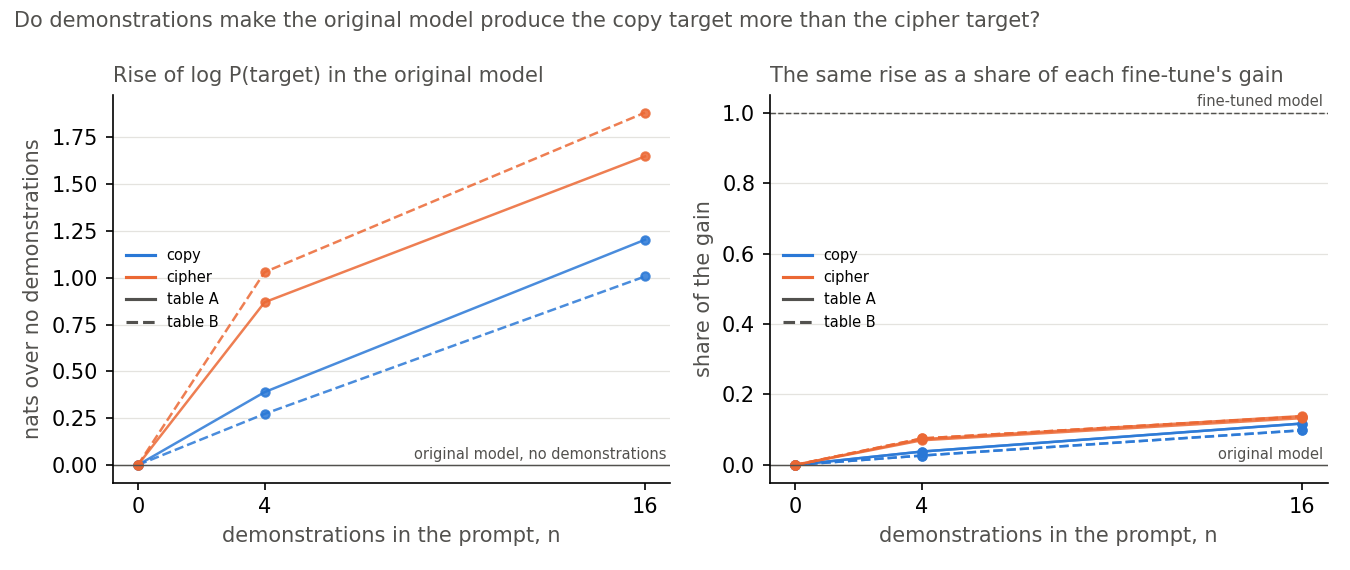

In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/baseline_neurons/figures")
display(Image(filename=str(FIG / "p4_prompting.png")))

**Reading it.** No: sixteen examples raise the cipher target slightly more than the copy target, the reverse of the filed expectation. The left panel shows the rise in nats. It is 1.0 to 1.2 for the copy tables and 1.6 to 1.9 for the cipher tables. The right panel divides by each fine-tune's gain, which is ten nats or more, so every share stays under 0.14. Copy reads 0.10 to 0.12 and cipher 0.13 to 0.14. The gap of 0.03 beats the spread within copy, 0.02. Both shares are near zero. The target's probability stays well under one in a thousand after sixteen examples, against roughly one in a million to one in ten thousand with none.

We cannot tell from this run why the reversal happened. Three readings fit, and each is a hypothesis:

- *The labels are wrong, or were never checked.* E12 called copy "existing" because the model has copying machinery. Immediate repetition right after a marker is something the original model gives about one in ten thousand. A copy share near 0.5 under a stronger prompt would support the label; staying near zero would not.
- *The prompt does not draw out in-context learning in a 4-layer model.* The examples sit in front of 19 tokens of unrelated text, not next to the query, with no separator. Placing them next to the query and adding the query's own pair as a positive control would test this.
- *Both numbers are near zero, so the comparison is between two nulls.* The filed rule had no minimum effect. The cipher's larger rise could be a shift of probability towards the pool of target words the examples show, not task skill. The query's own cipher target never appears in the demonstrations. Measuring the rise on target-pool words that are not the answer would separate this from learning.

### Does one added vector recover the copy fine-tunes but not the cipher fine-tunes?

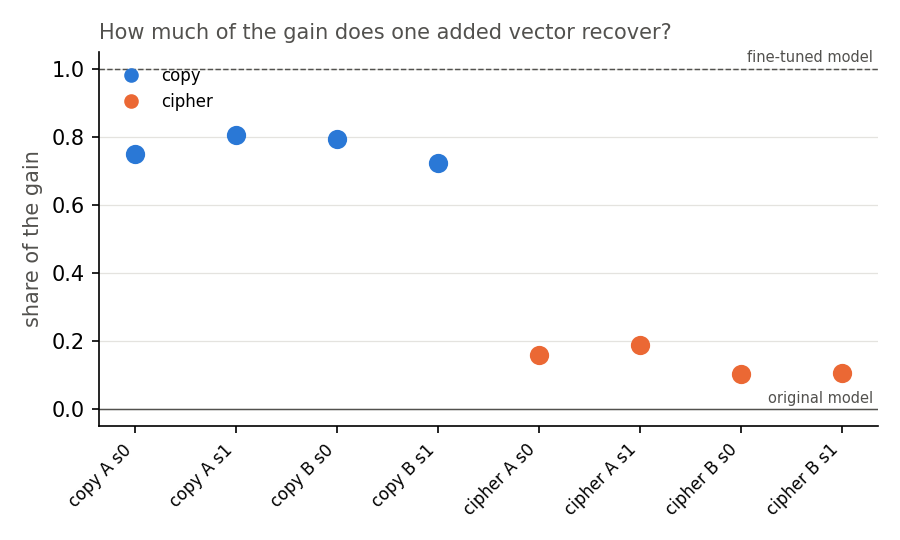

In [2]:
display(Image(filename=str(FIG / "p3_steering.png")))

**Reading it.** Yes, by a wide margin: one vector recovers 0.72 to 0.80 of each copy fine-tune's gain and 0.10 to 0.19 of each cipher fine-tune's. The gap between the kinds is 0.63, against a spread within either kind of 0.09. For copy the best vector sits at the third layer's input, for cipher at the last. The first layer's input is the token embedding, which no fine-tune changes, and its share reads zero as it must. The caveat is a hypothesis about the method: a fixed vector cannot depend on the key, and the cipher's answer does. So steering may separate these two tasks because one is key-dependent and the other is not, whatever the teach or elicit label says.

### Does a small set of neurons carry either fine-tune's change?

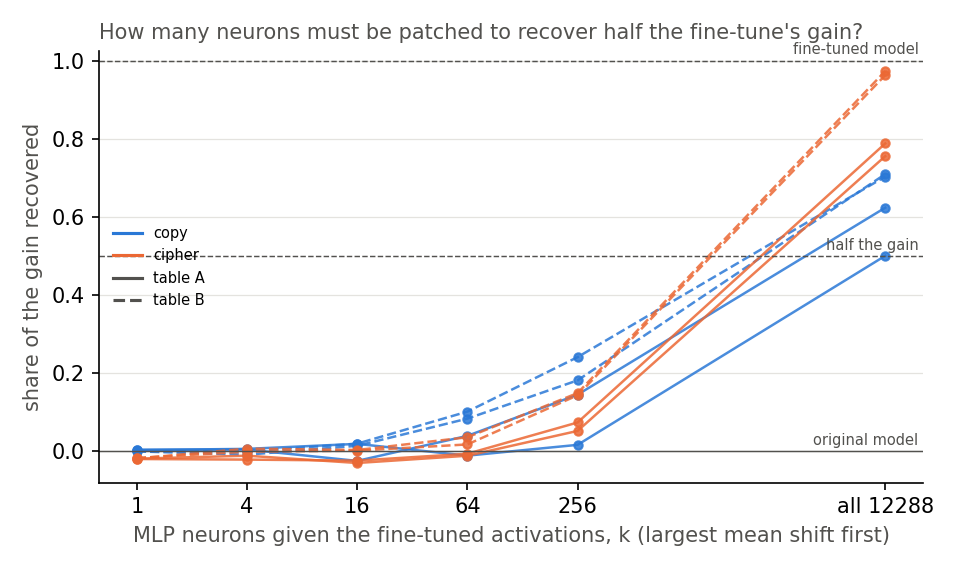

In [3]:
display(Image(filename=str(FIG / "p1_neuron_patch.png")))

**Reading it.** No: in all eight fine-tunes half the gain is reached only when every one of the 12288 neurons is patched. First read the right end of the figure, since it bounds what any subset can do. Patching all neurons recovers 0.50 to 0.71 for copy and 0.76 to 0.97 for cipher. This patch keeps the attention weights and the MLPs' output weights at their original values, so no subset of neurons can reach the rest of the gain. One copy fine-tune reaches 0.5001 at full width, so it clears half by a hair. At 256 neurons every share is at or under 0.24, and at 16 neurons every one is within 0.031 of zero. For neither kind do the most-shifted neurons, up to 256 of them, carry more than about a quarter of the change.

### Were the most-shifted neurons ones the original model left idle?

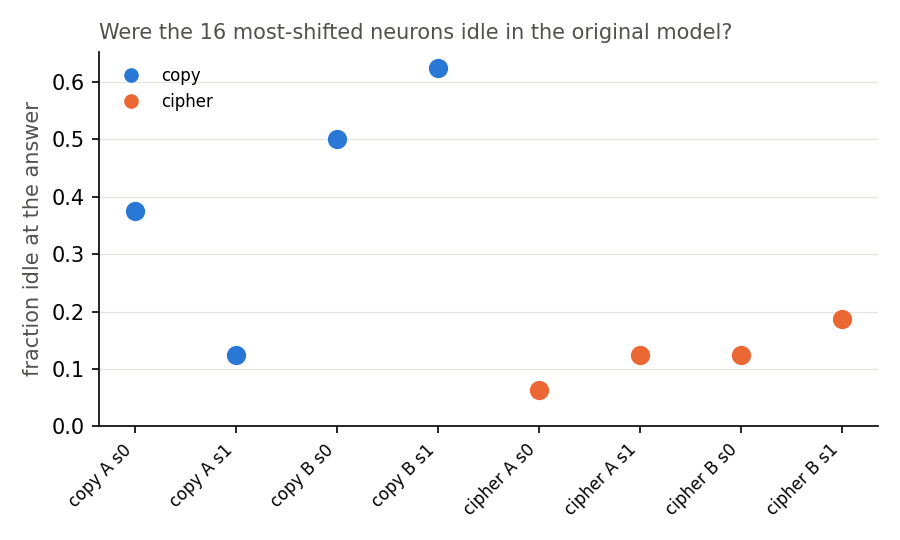

In [4]:
display(Image(filename=str(FIG / "p2_idle.png")))

**Reading it.** The kinds do not separate, and copy reads higher, opposite to the expectation. A neuron counts as idle when its mean activation at the answer is under a tenth of its typical large activation on Pile text. Copy reads 0.13 to 0.63 of its top 16 idle, cipher 0.06 to 0.19. The gap of 0.28 is smaller than the spread within copy of 0.5, which is within copy, from ident32_s1 at 0.125 to ident32b_s1 at 0.625. Since the top 16 neurons carry almost none of the gain, the idle share describes neurons whose patch recovers at most 0.03 of the gain.

### Does every method read the update that learned nothing as "no change"?

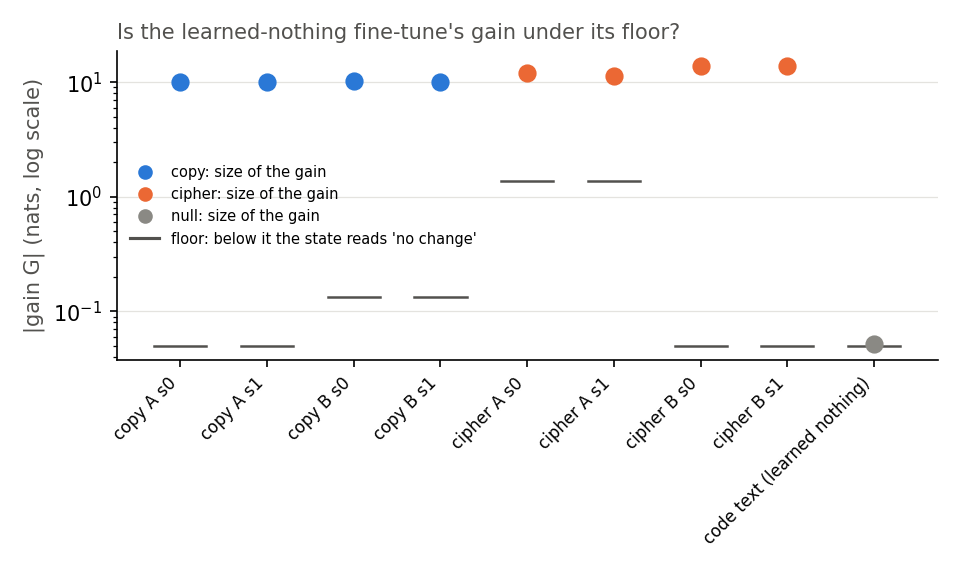

In [5]:
display(Image(filename=str(FIG / "p5_null.png")))

**Reading it.** Narrowly no: the code fine-tune's gain is −0.0514 nats against a floor of 0.05, so by the filed rule it counts as a change. Its gain is negative, so the update made held-out code slightly less likely. The eight task fine-tunes sit two orders of magnitude above their floors. None of the three methods was run on the code fine-tune, because it has no answer position and no worked examples; its verdict comes from the floor alone. A miss of 0.0014 nats depends on where the floor was put, and we give it one line rather than a reading.

## What we learned

The check on the labels failed, so the plan stops here for the user's decision. On these eight fine-tunes, neuron patching does not tell copy from cipher and steering does, by a wide margin. Steering's separation matches the direction of VPD's route split on the same set, so if the labels hold, a cheap activation method reproduces VPD's verdict here. But steering may be reading whether the change depends on the key rather than whether it is new. VPD's route split may be reading the same property. The pair that would tell them apart is a key-dependent mapping the original model already performs weakly.

## How compelling is the evidence

Eight fine-tunes in two kinds, two tables and two seeds each, on one model and one task format. The methods are deterministic given the states, so the only spread is between seeds and tables. Every share is scored on 48 held-out windows. The controls passed with margin: self-patching changed log probability by at most 2e-5 nats, and the last-layer patch recovered the gain to within 1e-7. Those controls test the hooks, not the methods' power to separate kinds; no method has a positive control of known kind. Neuron patching changes activations, not weights, so it cannot separate an MLP change from an attention change upstream. Steering is blind to key-dependent changes by construction. Prompting is blind to anything that cannot be shown as worked examples, and at these shares it is near zero.

## Surprises

Something unexpected happened that we cannot explain: prompting the original model with worked examples was predicted, with high confidence, to favour copy over cipher, and it favoured cipher by a small margin. Both shares were near zero, and the filed rule had no minimum effect, so the reversal may be between two nulls; the three readings above are untested. Patching every neuron recovered more of the cipher gain than of the copy gain, which no prediction addressed. The learned-nothing update missed its floor by 0.0014 nats.

## What next

The options, the lead's and the advisor's recommendation, are in `reports/decisions/2026-10-29_decision_e52-p4.md`; none is decided. The user chooses.

- Re-run prompting only, with examples next to the query, more of them, and a minimum effect. A copy share of at least half would mean the labels hold and steering's separation stands as the objection.
- Write up steering's separation with the key-dependence caveat, built on labels not yet checked.
- Build a key-dependent update the original model already performs weakly, and run steering and VPD's route split on it. If steering reads it as teach and VPD as elicit, that is the case where VPD adds something.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| S0 | hooks behave | self-patch ≤ 1e-4 nats; last-layer patch share 1 ± 1e-3; G > 1 nat | 1.7e-5; 1.0000000; 10.1 and 12.0 | pass |
| P1 | neurons needed for half the gain separate, copy fewer | gap of kind means > larger within-kind range | all at full width; gap 0, range 0 | fails |
| P2 | idle share of the top 16 separates, cipher higher | same | gap 0.28, range 0.50 | fails |
| P3 | steering share separates, copy higher | same | 0.77 vs 0.14; range 0.09 | pass |
| P4 | prompting share at 16 examples separates, copy higher | same | 0.11 vs 0.14; range 0.02 | reversed |
| P5 | learned-nothing update under the floor | \|G\| < 0.05 | 0.0514 | fails, by 0.0014 |

The filed decision tree reads P4's reversal as "the labels are not what we think: stop and tell the user".

## Not run

Prompting with examples next to the query, with the query's own pair, or with a minimum effect; any method on the learned-nothing update; a matched random update as a floor for the activation numbers; a size-matched copy and cipher pair; the key-dependent elicit pair; the dictionary and probe baselines of the scoping plan.

Provenance: `experiments/baseline_neurons/run.py`, results `experiments/baseline_neurons/results/baseline_neurons.json`, filed rules `results/predictions.json`, dated note on the window count `reports/predictions/2026-10-29_prediction_e52-window-count.md`. MATS cluster L40, debug QoS, job 44095, under a minute of measurement after loading, $0. Report: `reports/analyses/2026-10-29_analysis_e52-baseline-neurons.md`.

## Amendment 1: does the original model copy in context when the examples sit next to the query?

### The answer

No. We re-ran the label check with up to 31 worked examples placed right before the question, after a control showed the setup can see in-context copying. The original model then recovered about a fifth of the copy fine-tune's gain, slightly more than of the cipher's, and never ranked the answer first. So copying is a claim about the model's machinery, not shown in its behaviour here, and this check cannot vouch for either label.

### What we were trying to test

The prompting check above put the examples in front of 19 tokens of unrelated text. The user chose to re-run it once, fairly, before reading anything else. Only the original model is run, on the same 48 scoring windows per task. Each prompt is now the window's Pile text, then $n$ worked examples, then the marker and the query key, so the examples sit right next to the question. An example is a marker, a key and its target; for copy the target is the key itself. The query's own key is never shown, and at $n = 31$ every other key is shown once.

Three numbers are read. The **rise** is how much the examples raise the log probability of the target, in nats. The **share** divides the rise by each fine-tune's own gain, so 0 is the original model and 1 the fine-tuned one. The **top-1** is the fraction of windows where the target is the model's most likely next token.

A control ran first and alone, and would have stopped the job on a miss. The model reads a random sequence of 25 token ids shown twice. If it cannot predict the second showing, this setup cannot see in-context copying at all, and no prompting number would mean anything.

### What we expected, and why

The copy label would hold if the copy share at 31 examples reached half and stayed above the cipher's. A share from 0.3 to half would be "partial", and anything lower "mechanism only": the model has copying machinery but does not use it here. We leaned towards failure, with low confidence. In E52's far format the copy target stayed near three in ten thousand, but adjacent examples and more of them might help.

In [ ]:
display(Image(filename=str(FIG / "p4a_prompting_adjacent.png")))

**Reading it.** No: at 31 examples every copy share sits at 0.22, under the "partial" line, and the fine-tuned model reads 1. The cipher shares sit just below, at 0.18 to 0.19. The right panel shows the original model never ranks the target first, on any window, at any number of examples. Every top-1 value is exactly zero, so the four task lines overlap and only one colour shows. The dashed line at 0.82 is the control: on the repeated random sequence the model predicts most tokens of the second showing, and none of the first. So the model copies in context in its easiest form, but not in this format.

The control and the task differ in one way that matters. On the repeated sequence the model can find the same token earlier and copy what followed it. In the copy prompt the query key never appears earlier, so the model must pick up the rule "after the marker, repeat the key" from the examples. In this format the 4-layer model does not apply that rule well enough to reach the filed bar. The copy rise is 0.22 of the gain, and the cipher's target rises about as much.

Placing the examples next to the query raised every rise. Copy gained most only at 16 examples, where its rise grew by a factor of 1.72 and 1.81 over the far format. At 4 examples one cipher table gained the most of any task. Going from 16 to 31 adds at most 0.42 nats. The copy target ends near one in a thousand, an approximate reading from E12's per-key averages.

The copy share is above the cipher's at 31 examples by three hundredths, which beats the spread within either kind. That spread is small partly by coincidence: the two copy tables happen to agree, and one cipher table's larger rise is offset by its larger gain. With fewer examples the spread is wider and the kinds do not separate. The cipher's target never appears in the prompt, so its rise is probably a shift towards the shown words rather than skill; that is a hypothesis, not measured.

## What we learned

The copy label was never checked by behaviour, and this check does not supply it. The cipher label is not checked either. So neither steering's separation nor VPD's route split on these states can be scored against verified labels. The next step, E54, builds a key-dependent pair whose elicited value the original model already gives with probability 0.01 to 0.1, so no prompt is needed. One limit, noted by the user, applies to any such reading: a new circuit built from existing subcomponents also reads "elicited" to VPD's route split.

## How compelling is the evidence

The run is deterministic, with eight fine-tunes on four tasks and 48 windows each; the only spread is between tables and seeds. The control passed well over its bar, and the empty prompt reproduced E52's window to a millionth of a nat on average, and to 2e-5 nats on every window. The share counts any reason the target rises, and it compares the original model on a long prompt with the fine-tune on the bare window. Top-1 ignores probability below the most likely token. E12's averages suggest the target is on average far from the top, but its per-window rank was not measured. The control is blind to rule learning, which is what the copy prompt asks.

## Surprises

None reverses a filed prediction: the verdict fails, as leaned. The copy top-1 read zero, below its unscored lean of at least 0.05. The control read 0.82, below its unscored lean of 0.9 but far over its bar.

## Departures from the literature

- The control's bar of 0.5 is our own conservative number, not one from Olsson et al. 2022. That paper shows induction heads make a repeated random sequence predictable and reports loss, with no accuracy threshold. We read top-1 accuracy on a short sequence shown twice, because no number exists for a model this small and the rule had to be filed first.
- Prompting as a label check is credited to Lin et al. 2023, who draw chat behaviour out of base models of 7B parameters and up. They use a system prompt and three styled example conversations and judge generated answers. We use bare marker, key, value examples on a 4-layer model and read one token's probability. The bands of 0.5 and 0.3 are ours.
- Sampling over many tries, as in Yue et al. 2025, was not run; top-1 is a single greedy try.

## Amendment 1 scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| S0a | the control sees in-context copying | top-1 on the second showing ≥ 0.5 | 0.825; first showing 0.000 | pass |
| S0b | the empty prompt equals E52's window | tokens equal; mean rise ≤ 1e-5 nats; per-window max ≤ 1e-4 nats | equal; 1.1e-6; 2.0e-5 | pass |
| P4a | copy label holds behaviourally | copy mean share at 31 examples ≥ 0.5 and above cipher by more than the spread | 0.216, "mechanism only"; 0.216 vs 0.185, spread 0.008 | fails, as leaned |

## Amendment 1: not run

The query's own pair among the examples as a positive control in this format; the rise of non-answer words from the shown pool; formats with a separator or an instruction; sampling, or the target's rank below the top; more than 31 examples; any larger model; a behavioural test of the cipher label.

Provenance: `experiments/baseline_neurons/amend1.py`, `plot_amend1.py`, results `experiments/baseline_neurons/results/amend1.json`, filed rules `results/predictions_amend1.json`. MATS cluster, debug QoS, job 45898, 2026-10-30, about a second of measurement, $0. Report: `reports/analyses/2026-10-29_analysis_e52-baseline-neurons.md`, section "Amendment 1".